# Exercise 3 — M-dwarf flares at high cadence

*Covers notebooks 01, 03. Difficulty: ★★★☆☆*

One readout per exposure whatever the array size makes LFAST a natural flare spectrograph. How faint, how fast, and what does a flare look like?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

A fiber-combined array reads out once per exposure regardless of the number of telescopes, so
second-to-minute cadence spectroscopy of bright-ish stars is a natural niche: H$\alpha$, H$\beta$
and He I D3 during M-dwarf flares, chromospheric variability of exoplanet hosts, accretion
variability in young stars.

Assumptions: SNR 20 per resel in the continuum next to H$\alpha$ (650 to 660 nm) as the threshold
for a usable line profile per exposure; cadences of 10, 60 and 600 s; M dwarfs as 3300 K blackbodies
normalised in V, with $M_V$ = +10 (M3), +13 (M5) and +16 (M8) for the distance reach; grey sky.

**One cell in this exercise is broken on purpose.** It runs without error and makes a plausible
plot, but the physics is wrong. Find it.

In [2]:
WINDOW = (650, 660); SNR_LINE = 20
mdwarf = Source.blackbody(3300, 0, "V")
bench = LFASTETC("bench_r1800", n_telescopes=20)

### 3.1 — Faintest M dwarf with SNR 20 per resel at H-alpha

For cadences of 10, 60 and 600 s, what is the limiting V? Then the distance reach at 10 s cadence
for an M3, M5 and M8 dwarf.

> ✏️ **Before you run the next cell:** at 10 s cadence with 20 telescopes, how faint an M dwarf still gives SNR 20 per resel next to H-alpha? V = 12, 14 or 16? Write your guess down (or put it in the room poll), then run.

In [3]:
lims = {exp: bench.limiting_magnitude(mdwarf, exp, SNR_LINE, wavelength=WINDOW) for exp in (10, 60, 600)}
for exp, v in lims.items():
    print(f"{exp:4d} s cadence: V < {v:.1f}")
for label, MV in {"M3 (M_V=+10)": 10, "M5 (M_V=+13)": 13, "M8 (M_V=+16)": 16}.items():
    print(f"{label:14s} at 10 s cadence: {10**((lims[10] - MV + 5) / 5):6.1f} pc")

  10 s cadence: V < 14.1
  60 s cadence: V < 16.0
 600 s cadence: V < 18.3
M3 (M_V=+10)   at 10 s cadence:   64.9 pc
M5 (M_V=+13)   at 10 s cadence:   16.3 pc
M8 (M_V=+16)   at 10 s cadence:    4.1 pc


### 3.2 — A flare spectrum at 10 s cadence

During a large flare the blue continuum brightens by magnitudes while H$\alpha$ goes into strong
emission. Model the flare as the quiescent 3300 K star (V = 12) plus a 10,000 K blackbody component
that doubles the V flux (a 0.75 mag flare), with H$\alpha$ in emission (depth -3 on a 0.1 nm
Gaussian). The cell below builds the flare source. Check `flare.mag` before you plot.

In [4]:
wl = np.linspace(380, 1000, 4000)
quiet = Source.blackbody(3300, 12, "V")
hot = Source.blackbody(10000, 12, "V")
flare_flux = quiet.flux(wl) + hot.flux(wl)
# flux() returns an absolute spectrum in W/m2/nm: pass it as such and let the magnitude follow.
# With flux_unit="flam" and mag=12 the sum was renormalised back to V = 12, erasing the flare.
flare = Source.from_arrays(wl, flare_flux, flux_unit="W/m2/nm", band="V").add_line(656.3, -3.0, 0.1)
print(f"quiescent V = {quiet.mag:.2f}, flare V = {flare.mag:.2f}")

quiescent V = 12.00, flare V = 11.25


Plot the SNR per resel across the band in 10 s for the star quiet and in flare, for 20 and 200
telescopes. Which end of the spectrum gains the most, and why is that the end that matters?

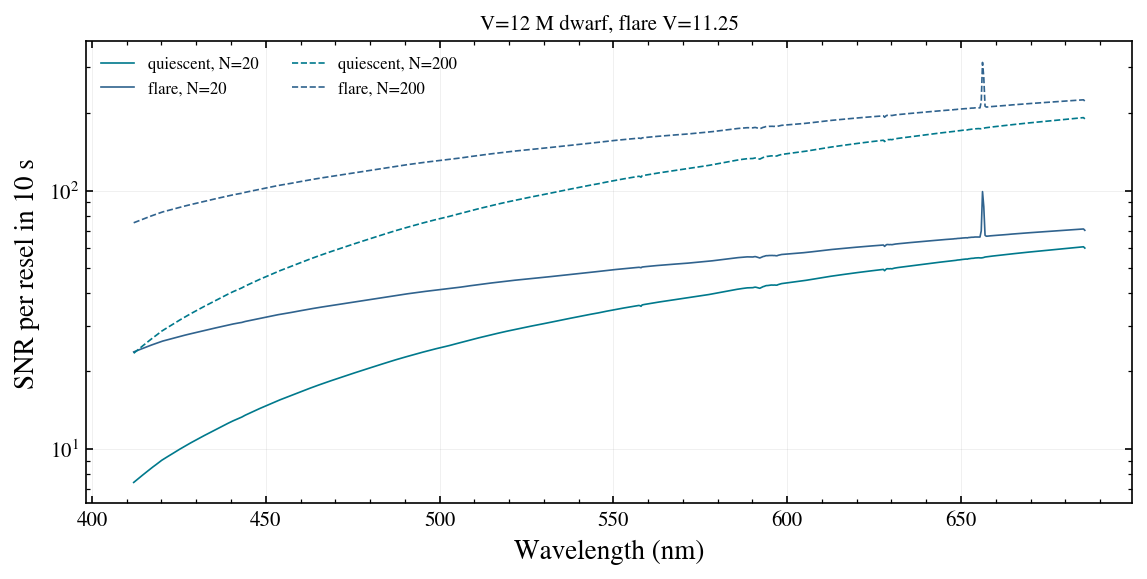

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for n, ls in ((20, "-"), (200, "--")):
    e = LFASTETC("bench_r1800", n_telescopes=n)
    ax.plot(e.wavelength, e.snr(quiet, 10).snr, ls=ls, color="C0", lw=0.8, label=f"quiescent, N={n}")
    ax.plot(e.wavelength, e.snr(flare, 10).snr, ls=ls, color="C3", lw=0.8, label=f"flare, N={n}")
ax.set_yscale("log"); ax.set_xlabel("Wavelength (nm)"); ax.set_ylabel("SNR per resel in 10 s")
ax.set_title(f"V=12 M dwarf, flare V={flare.mag:.2f}"); ax.legend(ncol=2)
# The blue end gains the most: that is where the Balmer jump and the hot continuum live.

### 3.3 — Exoplanet-host monitoring and the bright limit

SNR per resel at H$\alpha$ in a 60 s exposure for a V = 8 K dwarf (4800 K), a V = 11 and a V = 14
M dwarf, with 20 telescopes. Which one saturates the STA1 full well, and how many reads does
`reads_needed` say it needs?

In [6]:
hosts = {"V=8 K dwarf": (4800, 8), "V=11 M dwarf": (3300, 11), "V=14 M dwarf": (3300, 14)}
for label, (teff, mag) in hosts.items():
    s = Source.blackbody(teff, mag, "V")
    r = bench.snr(s, 60)
    n = bench.reads_needed(s, 60)
    rn = bench.snr(s, 60, n_exp=n)
    print(f"{label:14s} 60 s at H-alpha: SNR={r.at(656.3)['snr']:6.0f}" + (f" (saturated! {n} reads -> SNR={rn.at(656.3)['snr']:.0f})" if r.saturated.any() else ""))

V=8 K dwarf    60 s at H-alpha: SNR=   706 (saturated! 2 reads -> SNR=706)
V=11 M dwarf   60 s at H-alpha: SNR=   216
V=14 M dwarf   60 s at H-alpha: SNR=    53


> 🤖 **Ask Jupyter AI:** *Plot the limiting V for SNR 20 at H-alpha against the number of telescopes (1 to 200, log axis) for the 10 s and 60 s cadences, with equivalent_diameter_axis on top. At what array size does a V = 13 M dwarf come within reach at 10 s?*

***
## Share-back and feedback

Bring back **one plot and one number** to the share-back board, and the observing decision you draw
from them.

> 🤖 **Ask Jupyter AI:** *Draft a GitHub issue for schmidt-observatories/lfast-etc describing one thing I
> found missing, confusing or wrong in this exercise, with a minimal code example.*